# Notebook Verifikasi — Q-Tunnel Lab
**Proyek Fisika Kuantum · Kelompok 7 · Luaran Pekan 12**

Ernauli Br. Haloho · Heny Asvarinda · Dila Badiro (Analis-Programmer)

Notebook ini adalah acuan kebenaran perhitungan untuk *Quantum Tunneling Interactive Lab*. Isinya:
1. Implementasi analitik koefisien transmisi $T$ untuk ketiga daerah energi (pers. 2–4).
2. Solusi numerik independen: integrasi RK4 Persamaan Schrödinger (pers. 1) dan metode matriks transfer.
3. Grafik $T(E)$, $R(E)$, $T(a)$, $|\psi|^2$, dan limit klasik.
4. Tabel nilai untuk parameter contoh (elektron, $V_0 = 5$ eV, $a = 0{,}4$ nm).
5. Pemeriksaan kebenaran fisika sesuai Lampiran proposal, dengan tabel ringkasan.

Satuan: energi dalam eV, panjang dalam nm, massa dalam kelipatan $m_e$; $\hbar^2/2m_e = 0{,}0380998$ eV·nm².

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .3, 'font.size': 10})
OUT = Path('grafik'); OUT.mkdir(exist_ok=True)

H2M = 0.0380998          # hbar^2 / (2 m_e)  [eV nm^2]
V0, A, M_E = 5.0, 0.4, 1.0   # parameter contoh proposal
print('NumPy', np.__version__)

NumPy 2.5.3


## 1. Model fisika dan solusi analitik
Persamaan Schrödinger tak bergantung waktu:
$$-\frac{\hbar^2}{2m}\frac{d^2\psi}{dx^2}+V(x)\psi=E\psi,\qquad V(x)=\begin{cases}V_0 & 0<x<a\\ 0 & \text{lainnya}\end{cases}\tag{1}$$

Dengan syarat kontinuitas $\psi$ dan $d\psi/dx$ di $x=0$ dan $x=a$:

| Daerah | Koefisien transmisi |
|---|---|
| $0<E<V_0$ | $T=\left[1+\dfrac{V_0^2\sinh^2(\kappa a)}{4E(V_0-E)}\right]^{-1},\ \kappa=\sqrt{2m(V_0-E)}/\hbar$ (2) |
| $E>V_0$ | $T=\left[1+\dfrac{V_0^2\sin^2(k'a)}{4E(E-V_0)}\right]^{-1},\ k'=\sqrt{2m(E-V_0)}/\hbar$ (3) |
| $E=V_0$ | $T=\left[1+\dfrac{mV_0a^2}{2\hbar^2}\right]^{-1}$ (4) |

dan $R = 1-T$. Prediksi klasik: $T_\text{klasik}=0$ untuk $E<V_0$, $1$ untuk $E>V_0$.

In [2]:
def T_analitik(E, V0=V0, a=A, m=M_E):
    """Koefisien transmisi analitik, pers. (2)-(4). E boleh skalar atau array."""
    E = np.atleast_1d(np.asarray(E, dtype=float))
    T = np.empty_like(E)
    eq = np.isclose(E, V0, rtol=1e-9, atol=0)
    lo, hi = (E < V0) & ~eq, (E > V0) & ~eq
    ka = np.sqrt(m * (V0 - E[lo]) / H2M) * a
    T[lo] = 1 / (1 + V0**2 * np.sinh(ka)**2 / (4 * E[lo] * (V0 - E[lo])))
    kpa = np.sqrt(m * (E[hi] - V0) / H2M) * a
    T[hi] = 1 / (1 + V0**2 * np.sin(kpa)**2 / (4 * E[hi] * (E[hi] - V0)))
    T[eq] = 1 / (1 + m * V0 * a**2 / (4 * H2M))
    T[E <= 0] = 0
    return T if T.size > 1 else T[0]

def T_klasik(E, V0=V0):
    return np.where(np.asarray(E) > V0, 1.0, 0.0)

kappa_a = np.sqrt(M_E * (V0 - 3) / H2M) * A
print(f'Contoh proposal: E = 3 eV -> kappa*a = {kappa_a:.4f},  T = {T_analitik(3.0)*100:.4f} %')

Contoh proposal: E = 3 eV -> kappa*a = 2.8981,  T = 1.1605 %


## 2. Solusi numerik independen
**(a) Integrasi RK4.** Mulai dari $x=a$ dengan gelombang keluar $\psi=e^{ikx}$, integrasikan pers. (1) mundur ke $x=0$, lalu uraikan $\psi(0)=A+B$, $\psi'(0)=ik(A-B)$. Maka $T=1/|A|^2$ dan $R=|B|^2/|A|^2$.

**(b) Matriks transfer.** Mencocokkan $(\psi,\psi')$ di kedua batas melalui perkalian matriks 2×2.

Kedua metode tidak memakai rumus (2)–(4), sehingga menjadi pembanding yang sah.

In [3]:
def T_numerik_rk4(E, V0=V0, a=A, m=M_E, N=4000):
    k = np.sqrt(m * E / H2M)
    f = m * (V0 - E) / H2M                      # psi'' = f psi di dalam penghalang
    y = np.array([np.exp(1j*k*a), 1j*k*np.exp(1j*k*a)])
    h = -a / N
    F = lambda y: np.array([y[1], f * y[0]])
    for _ in range(N):
        k1 = F(y); k2 = F(y + h/2*k1); k3 = F(y + h/2*k2); k4 = F(y + h*k3)
        y = y + h/6 * (k1 + 2*k2 + 2*k3 + k4)
    Aamp = 0.5 * (y[0] + y[1] / (1j*k))
    Bamp = 0.5 * (y[0] - y[1] / (1j*k))
    return 1/abs(Aamp)**2, abs(Bamp)**2/abs(Aamp)**2

def T_matriks_transfer(E, V0=V0, a=A, m=M_E):
    k = np.sqrt(m * E / H2M + 0j)
    q = np.sqrt(m * (E - V0) / H2M + 0j)
    if abs(q) < 1e-12: q = 1e-9 + 0j
    Mx = lambda kk, x: np.array([[np.exp(1j*kk*x), np.exp(-1j*kk*x)],
                                 [1j*kk*np.exp(1j*kk*x), -1j*kk*np.exp(-1j*kk*x)]])
    Mt = np.linalg.solve(Mx(k, 0), Mx(q, 0)) @ np.linalg.solve(Mx(q, a), Mx(k, a))
    return float(abs(1 / Mt[0, 0])**2)

Tn, Rn = T_numerik_rk4(3.0)
print(f'E = 3 eV: analitik {T_analitik(3.0):.10e} | RK4 {Tn:.10e} | TMM {T_matriks_transfer(3.0):.10e}')

E = 3 eV: analitik 1.1605028403e-02 | RK4 1.1605028403e-02 | TMM 1.1605028403e-02


## 3. Tabel nilai — elektron, $V_0 = 5$ eV, $a = 0{,}4$ nm

In [4]:
E_tab = np.array([0.5, 1, 2, 3, 4, 4.5, 5 - 1e-9, 5, 5.5, 6, 7, 7.3502, 8, 10])
rows = []
for E in E_tab:
    Ta = T_analitik(E)
    Tr, Rr = T_numerik_rk4(E if E != V0 else V0*(1+1e-9))
    Tt = T_matriks_transfer(E)
    rows.append(dict(**{'E (eV)': E, 'Rezim': 'E<V0' if E < V0-1e-6 else ('E=V0' if abs(E-V0) < 1e-6 else 'E>V0'),
                     'T analitik': Ta, 'T RK4': Tr, 'T matriks': Tt, 'R = 1-T': 1-Ta,
                     'Galat rel. RK4': abs(Tr-Ta)/Ta, 'T+R (RK4)': Tr+Rr, 'T klasik': float(T_klasik(E))}))
tabel = pd.DataFrame(rows)
tabel.to_csv(OUT / 'tabel_nilai.csv', index=False)
tabel.style.format({'E (eV)': '{:.4f}', 'T analitik': '{:.6e}', 'T RK4': '{:.6e}', 'T matriks': '{:.6e}',
                    'R = 1-T': '{:.6e}', 'Galat rel. RK4': '{:.1e}', 'T+R (RK4)': '{:.12f}', 'T klasik': '{:.0f}'})

,E (eV),Rezim,T analitik,T RK4,T matriks,R = 1-T,Galat rel. RK4,T+R (RK4),T klasik
0,0.5000,E<V0,2.412761e-04,2.412761e-04,2.412761e-04,9.997587e-01,9.3e-14,1.000000000000,0
1,1.0000,E<V0,7.050676e-04,7.050676e-04,7.050676e-04,9.992949e-01,7.8e-14,1.000000000000,0
2,2.0000,E<V0,3.167167e-03,3.167167e-03,3.167167e-03,9.968328e-01,3.6e-14,1.000000000000,0
3,3.0000,E<V0,1.160503e-02,1.160503e-02,1.160503e-02,9.883950e-01,1.1e-14,1.000000000000,0
4,4.0000,E<V0,4.208550e-02,4.208550e-02,4.208550e-02,9.579145e-01,4.3e-15,1.000000000000,0
5,4.5000,E<V0,8.165669e-02,8.165669e-02,8.165669e-02,9.183433e-01,1.0e-15,1.000000000000,0
6,5.0000,E=V0,1.600161e-01,1.600161e-01,1.600161e-01,8.399839e-01,1.3e-09,1.000000000000,0
7,5.0000,E=V0,1.600161e-01,1.600161e-01,1.600161e-01,8.399839e-01,6.7e-09,1.000000000000,0
8,5.5000,E>V0,3.087175e-01,3.087175e-01,3.087175e-01,6.912825e-01,2.2e-15,1.000000000000,1
9,6.0000,E>V0,5.491956e-01,5.491956e-01,5.491956e-01,4.508044e-01,3.4e-15,1.000000000000,1


## 4. Grafik $T(E)$ dan $R(E)$ — analitik vs numerik vs klasik

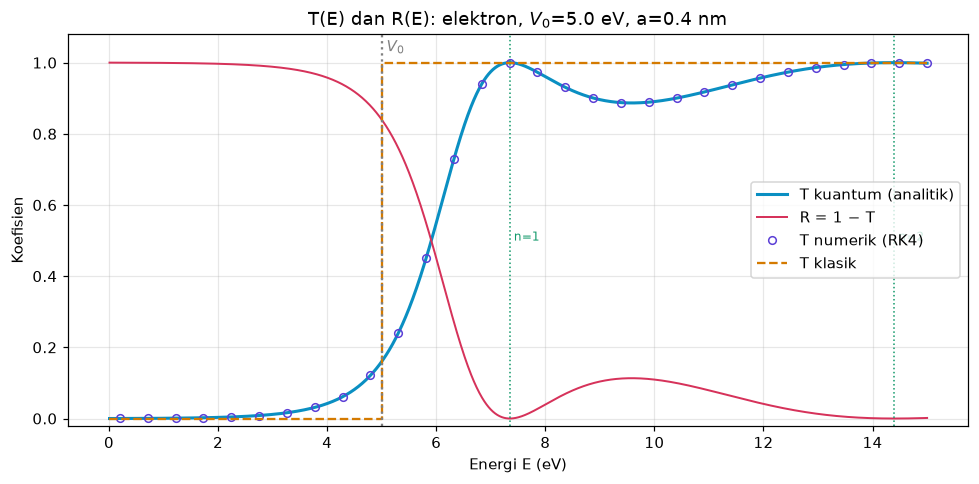

In [5]:
E = np.linspace(0.01, 3*V0, 1500)
T = T_analitik(E)
En = np.linspace(0.2, 3*V0, 30)
Tnum = [T_numerik_rk4(e if abs(e-V0) > 1e-9 else V0*(1+1e-9), N=1500)[0] for e in En]
E_res = [V0 + H2M*(n*np.pi/A)**2/M_E for n in (1, 2, 3)]

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(E, T, color='#0a8fc2', lw=2, label='T kuantum (analitik)')
ax.plot(E, 1-T, color='#d6325a', lw=1.3, label='R = 1 − T')
ax.plot(En, Tnum, 'o', ms=5, mfc='none', color='#5b3fd6', label='T numerik (RK4)')
ax.step([0, V0, 3*V0], [0, 1, 1], where='post', ls='--', color='#d47a00', label='T klasik')
ax.axvline(V0, color='gray', ls=':'); ax.text(V0, 1.03, ' $V_0$', color='gray')
for n, er in enumerate(E_res, 1):
    if er < 3*V0: ax.axvline(er, color='#11996a', ls=':', lw=1); ax.text(er, .5, f' n={n}', color='#11996a', fontsize=8)
ax.set(xlabel='Energi E (eV)', ylabel='Koefisien', ylim=(-.02, 1.08),
       title=f'T(E) dan R(E): elektron, $V_0$={V0} eV, a={A} nm')
ax.legend(loc='center right'); fig.tight_layout(); fig.savefig(OUT/'grafik_T_E.png'); plt.show()

## 5. Grafik $T(a)$ — eksak vs pendekatan penghalang tebal (pers. 5)
$$T\approx16\frac{E}{V_0}\left(1-\frac{E}{V_0}\right)e^{-2\kappa a}\tag{5}$$

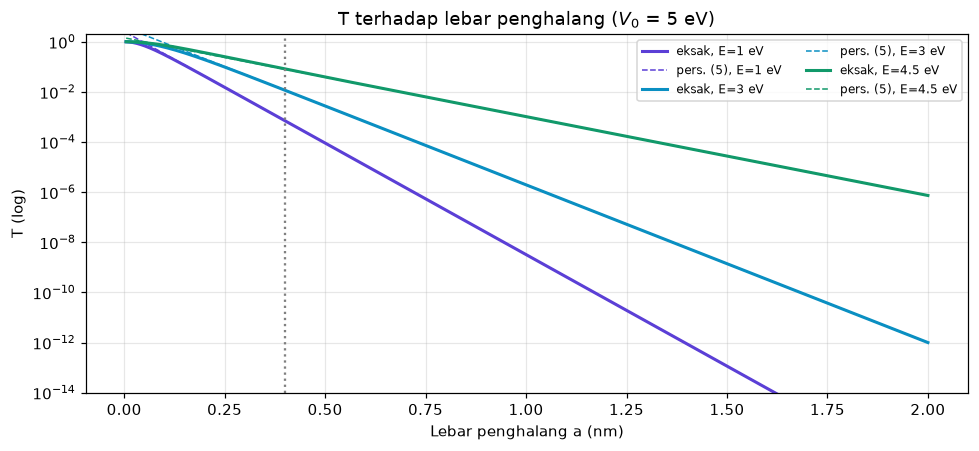

In [6]:
a = np.linspace(0.005, 2, 600)
fig, ax = plt.subplots(figsize=(9, 4.2))
for Ei, c in [(1, '#5b3fd6'), (3, '#0a8fc2'), (4.5, '#11996a')]:
    kap = np.sqrt(M_E*(V0-Ei)/H2M)
    ax.semilogy(a, [T_analitik(Ei, a=x) for x in a], color=c, lw=2, label=f'eksak, E={Ei} eV')
    ax.semilogy(a, 16*(Ei/V0)*(1-Ei/V0)*np.exp(-2*kap*a), '--', color=c, lw=1, label=f'pers. (5), E={Ei} eV')
ax.axvline(A, color='gray', ls=':'); ax.set(xlabel='Lebar penghalang a (nm)', ylabel='T (log)',
       title='T terhadap lebar penghalang ($V_0$ = 5 eV)', ylim=(1e-14, 2))
ax.legend(ncol=2, fontsize=8); fig.tight_layout(); fig.savefig(OUT/'grafik_T_a.png'); plt.show()

## 6. Fungsi gelombang $|\psi(x)|^2$ untuk tiga daerah energi

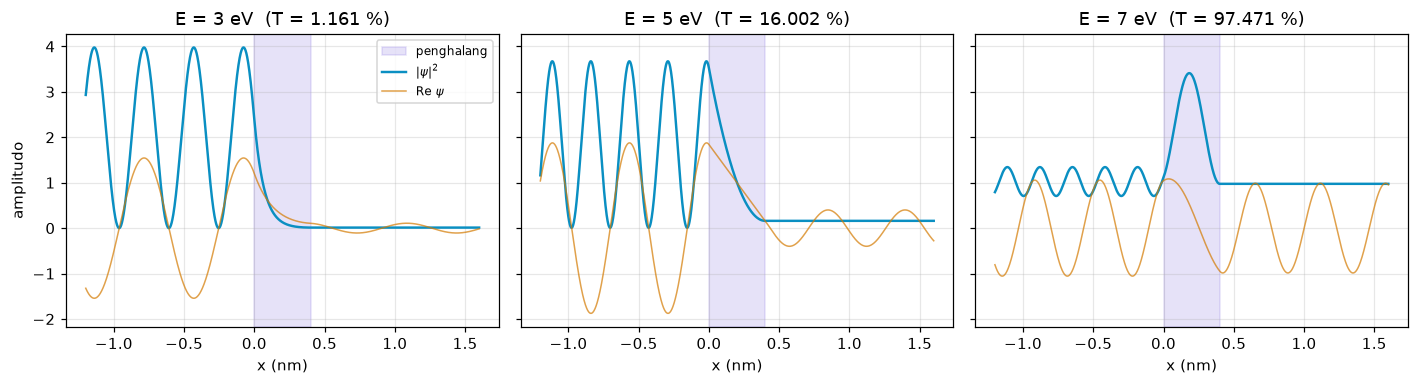

In [7]:
def psi(x, E, V0=V0, a=A, m=M_E):
    if abs(E-V0) < 1e-9: E = V0 + 1e-9
    k = np.sqrt(m*E/H2M); q = np.sqrt(m*(E-V0)/H2M + 0j)
    C1 = np.exp(1j*k*a)*(1 + k/q)/2*np.exp(-1j*q*a)
    D1 = np.exp(1j*k*a)*(1 - k/q)/2*np.exp(1j*q*a)
    t = 2 / (C1*(1 + q/k) + D1*(1 - q/k)); Cc, Dc = C1*t, D1*t; r = Cc + Dc - 1
    return np.where(x < 0, np.exp(1j*k*x) + r*np.exp(-1j*k*x),
           np.where(x <= a, Cc*np.exp(1j*q*x) + Dc*np.exp(-1j*q*x), t*np.exp(1j*k*x)))

x = np.linspace(-1.2, A+1.2, 2000)
fig, axs = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for ax, Ei in zip(axs, [3, 5, 7]):
    p = np.abs(psi(x, Ei))**2
    ax.axvspan(0, A, color='#5b3fd6', alpha=.15, label='penghalang')
    ax.plot(x, p, color='#0a8fc2', lw=1.6, label='$|\\psi|^2$')
    ax.plot(x, psi(x, Ei).real, color='#d47a00', lw=1, alpha=.7, label='Re $\\psi$')
    ax.set(title=f'E = {Ei} eV  (T = {T_analitik(Ei)*100:.3f} %)', xlabel='x (nm)')
axs[0].set_ylabel('amplitudo'); axs[0].legend(fontsize=8)
fig.tight_layout(); fig.savefig(OUT/'grafik_psi.png'); plt.show()

## 7. Classical Limit Explorer — $T$ terhadap massa partikel
Untuk $E<V_0$ transmisi turun eksponensial terhadap $\sqrt{m}$; untuk $E>V_0$ transmisi berosilasi (resonansi) sehingga mendekati klasik **tidak monoton**.

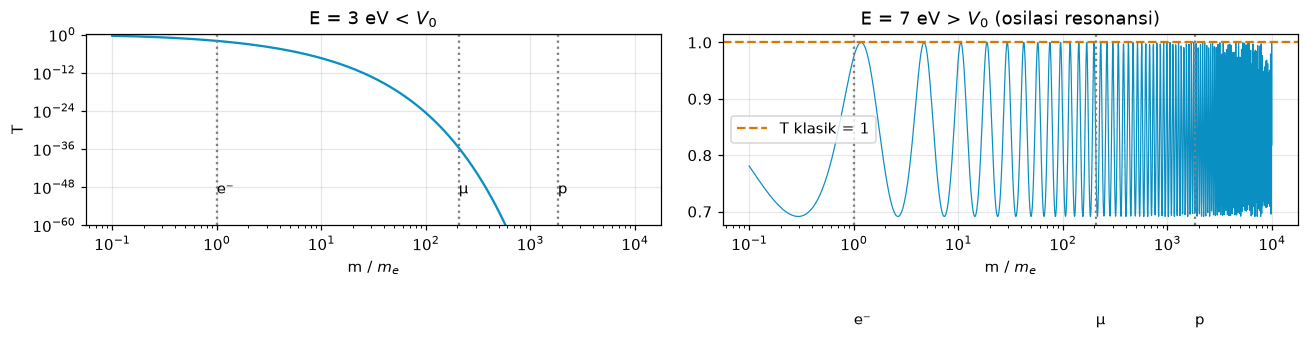

In [8]:
m = np.logspace(-1, 4, 2000)
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
axs[0].loglog(m, [T_analitik(3, m=mi) for mi in m], color='#0a8fc2'); axs[0].set(title='E = 3 eV < $V_0$', xlabel='m / $m_e$', ylabel='T', ylim=(1e-60, 2))
axs[1].semilogx(m, [T_analitik(7, m=mi) for mi in m], color='#0a8fc2', lw=.8); axs[1].axhline(1, ls='--', color='#d47a00', label='T klasik = 1')
axs[1].set(title='E = 7 eV > $V_0$ (osilasi resonansi)', xlabel='m / $m_e$'); axs[1].legend()
for ax in axs:
    for mm, lb in [(1, 'e⁻'), (206.77, 'μ'), (1836.15, 'p')]: ax.axvline(mm, color='gray', ls=':'); ax.text(mm, .5 if ax is axs[1] else 1e-50, lb)
fig.tight_layout(); fig.savefig(OUT/'grafik_limit_klasik.png'); plt.show()

## 8. Pemeriksaan kebenaran fisika (Lampiran proposal bagian c)

In [9]:
cek = []
def catat(nama, lulus, detail): cek.append(dict(Kriteria=nama, Status='LULUS ✓' if lulus else 'GAGAL ✗', Detail=detail))

Es = np.r_[np.linspace(0.2, 4.9, 12), np.linspace(5.1, 15, 12)]
hasil = [T_numerik_rk4(e) for e in Es]
cons = max(abs(t + r - 1) for t, r in hasil)
err = max(abs(t - T_analitik(e)) / T_analitik(e) for e, (t, _) in zip(Es, hasil))
catat('Kekekalan probabilitas T + R = 1', cons < 1e-6, f'max |T+R−1| = {cons:.2e}')
catat('Kesesuaian analitik–numerik < 1e-6', err < 1e-6, f'galat relatif maks = {err:.2e}')
tm = max(abs(T_matriks_transfer(e) - T_analitik(e)) / T_analitik(e) for e in Es)
catat('Kesesuaian dengan matriks transfer', tm < 1e-8, f'galat relatif maks = {tm:.2e}')
lo, eq, hi = T_analitik(V0*(1-1e-7)), T_analitik(V0), T_analitik(V0*(1+1e-7))
catat('Kontinuitas di E = V0', max(abs(lo-eq), abs(hi-eq))/eq < 1e-5, f'{lo:.8f} | {eq:.8f} | {hi:.8f}')
tt = T_analitik(3, a=1e-6); catat('Penghalang tipis a→0 ⇒ T→1', tt > 0.9999, f'a = 1e-6 nm → T = {tt:.10f}')
kap = np.sqrt((V0-3)/H2M); ath = 8/kap; ex, ap = T_analitik(3, a=ath), 16*.6*.4*np.exp(-2*kap*ath)
catat('Penghalang tebal sesuai pers. (5)', abs(ap-ex)/ex < 1e-3, f'κa = 8: eksak {ex:.4e}, aproks {ap:.4e}')
rs = [T_analitik(V0 + H2M*(n*np.pi/A)**2) for n in (1, 2, 3)]
catat("Resonansi T = 1 saat k'a = nπ", all(abs(r-1) < 1e-12 for r in rs), 'T(n=1,2,3) = ' + ', '.join(f'{r:.12f}' for r in rs))
te, tp = T_analitik(3, m=1), T_analitik(3, m=1836.15)
catat('Massa besar → mendekati klasik', tp < 1e-10 < te, f'elektron {te:.3e}, proton {tp:.3e}')
catat('Nilai contoh proposal T ≈ 1,16 %', abs(T_analitik(3)*100 - 1.16) < .01, f'T = {T_analitik(3)*100:.4f} %, κa = {kappa_a:.3f}')

ringkas = pd.DataFrame(cek)
ringkas.to_csv(OUT/'ringkasan_verifikasi.csv', index=False)
print(f"{sum(c['Status'].startswith('LULUS') for c in cek)} dari {len(cek)} kriteria lulus")
ringkas

9 dari 9 kriteria lulus


,Kriteria,Status,Detail
0,Kekekalan probabilitas T + R = 1,LULUS ✓,max |T+R−1| = 6.00e-15
1,Kesesuaian analitik–numerik < 1e-6,LULUS ✓,galat relatif maks = 1.14e-13
2,Kesesuaian dengan matriks transfer,LULUS ✓,galat relatif maks = 9.29e-16
3,Kontinuitas di E = V0,LULUS ✓,0.16001599 | 0.16001609 | 0.16001620
4,Penghalang tipis a→0 ⇒ T→1,LULUS ✓,a = 1e-6 nm → T = 0.9999999999
5,Penghalang tebal sesuai pers. (5),LULUS ✓,"κa = 8: eksak 4.3213e-07, aproks 4.3214e-07"
6,Resonansi T = 1 saat k'a = nπ,LULUS ✓,"T(n=1,2,3) = 1.000000000000, 1.000000000000, 1..."
7,Massa besar → mendekati klasik,LULUS ✓,"elektron 1.161e-02, proton 5.236e-108"
8,"Nilai contoh proposal T ≈ 1,16 %",LULUS ✓,"T = 1.1605 %, κa = 2.898"


## 9. Kesimpulan
- Solusi analitik (pers. 2–4) cocok dengan dua metode numerik independen (RK4 dan matriks transfer) dengan galat relatif jauh di bawah $10^{-6}$.
- Kekekalan probabilitas, kontinuitas di $E=V_0$, limit penghalang tipis/tebal, dan resonansi terpenuhi.
- Untuk parameter contoh (elektron, $V_0=5$ eV, $a=0{,}4$ nm, $E=3$ eV) diperoleh $\kappa a\approx2{,}90$ dan $T\approx1{,}16\%$. Nilai ini dipakai untuk mengoreksi angka ilustratif pada rancangan antarmuka.
- Fungsi yang sama dipakai di `server/physics.py` (mesin Python aplikasi web) dan `assets/physics.js` (mesin JavaScript).

Semua grafik dan tabel tersimpan di folder `grafik/` untuk lampiran artikel.